# 04 — Races: survival curves

The bearers of the Nine fell; the Dwarves did not submit. This notebook gives each race its own distribution of will and ambition, its own recovery rate $\gamma$, and for Dwarves a side effect: a share $\kappa$ of the ring's pull feeds **greed** instead of submission,

$$\frac{dG}{dt} = \kappa\,\alpha u A, \qquad \frac{dC}{dt} = (1-\kappa)\,\alpha u A(1+\beta C) - \gamma W (1 - C) \;(+\;\sigma\,\text{noise}).$$

Fall times from the stochastic model are right-censored at a 200-year horizon and compared with Kaplan–Meier estimators (`lifelines`). Every number here is an invented assumption.

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from corruption.plotting import plot_survival_curves
from corruption.races import (
    RACES,
    kaplan_meier,
    median_fall_times,
    pairwise_logrank,
    survival_at,
    survival_table,
)
from corruption.stochastic import SDEConfig

FIGURES = Path("../docs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 20261023
base = SDEConfig(sigma=0.02, dt=0.05, t_max=200.0)
pd.DataFrame([vars(r) for r in RACES.values()]).set_index("name")

,W_mean,A_mean,c0_mean,concentration,gamma,greed_share,description
name,,,,,,,
Men,0.55,0.80,0.05,20.0,0.020,0.0,High ambition; the Nine were given to Men.
Dwarves,0.60,0.70,0.05,20.0,0.025,0.5,Tough (high γ); the ring feeds greed for gold ...
Elves,0.85,0.45,0.02,20.0,0.030,0.0,Control group with strong will and little ambi...


In [2]:
table = survival_table(n_per_race=3000, base=base, seed=SEED, n_workers=2)
table.groupby("race", observed=True).agg(
    bearers=("fell", "size"),
    fallen=("fell", "mean"),
    mean_W=("W", "mean"),
    mean_A=("A", "mean"),
    mean_greed=("greed", "mean"),
).round(3)

,bearers,fallen,mean_W,mean_A,mean_greed
race,,,,,
Men,3000,0.999,0.547,0.799,0.000
Dwarves,3000,0.170,0.600,0.700,1.295
Elves,3000,0.016,0.851,0.449,0.000


## Kaplan–Meier survival curves

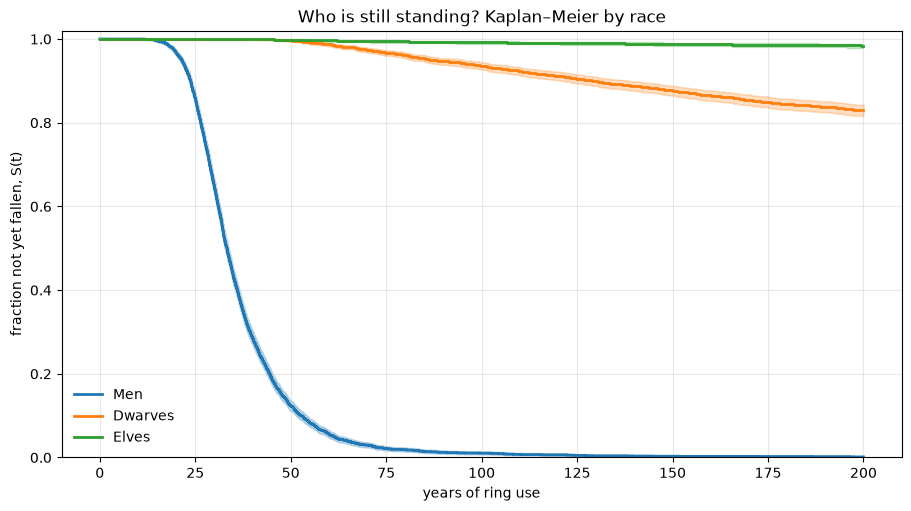

In [3]:
fitters = kaplan_meier(table)
fig = plot_survival_curves(fitters, title="Who is still standing? Kaplan–Meier by race")
fig.savefig(FIGURES / "survival_by_race.png", dpi=150)
plt.show()

In [4]:
pd.concat(
    [median_fall_times(fitters)] + [survival_at(fitters, t) for t in (25, 50, 100, 200)],
    axis=1,
).round(3)

,median fall time,S(25),S(50),S(100),S(200)
Men,33.332,0.858,0.124,0.010,0.001
Dwarves,inf,1.000,0.997,0.937,0.830
Elves,inf,1.000,0.998,0.992,0.984


Men fall quickly: high ambition against moderate will. Most Dwarves are still standing at 200 years, and so are almost all Elves. The log-rank test confirms that the curves differ:

In [5]:
pairwise_logrank(table).round(6)

,race A,race B,statistic,p
0,Men,Dwarves,7261.833282,0.0
1,Men,Elves,7392.961369,0.0
2,Dwarves,Elves,422.717277,0.0


## The greed side effect

How much of the Dwarves' resistance comes from the greed diversion rather than from their higher $\gamma$? Turn it off ($\kappa = 0$) and run the same seed again.

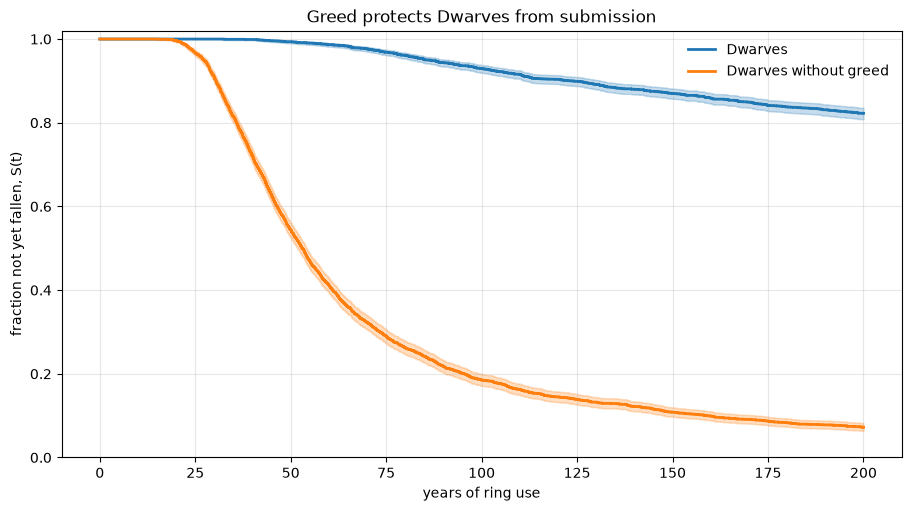

Dwarves                   inf
Dwarves without greed    53.0
Name: median fall time, dtype: float64

In [6]:
no_greed = {
    "Dwarves": RACES["Dwarves"],
    "Dwarves without greed": replace(
        RACES["Dwarves"], name="Dwarves without greed", greed_share=0.0
    ),
}
compare = survival_table(no_greed, n_per_race=3000, base=base, seed=SEED, n_workers=2)
compare_fitters = kaplan_meier(compare)
fig = plot_survival_curves(compare_fitters, title="Greed protects Dwarves from submission")
fig.savefig(FIGURES / "dwarves_greed.png", dpi=150)
plt.show()
median_fall_times(compare_fitters).round(1)

Without the side effect, half of the Dwarves fall within about 50 years, not far behind Men (about 33). The diversion of the ring's pull into greed, not tougher character alone, is what keeps them from becoming wraiths. They pay for it in gold-lust instead.

Survival analysis is the same tool used for component reliability: replace "bearer" with "bearing" and "fall" with "failure".